# From Collision to Consequence — Analysis Notebook

## What this notebook is about

Every year, UK police record every road crash where someone got hurt. This is called the **STATS19** dataset. This notebook uses it to answer one question:

> **Once someone is hurt in a crash, what decides whether they walk away with a bruise, or end up killed or seriously injured?**

We are not asking "how likely am I to crash" — we don't have mileage data for that. We only look at people who were **already** hurt, and ask what made their injury better or worse.

## How the notebook is organised: four steps, not a pile of charts

Each step builds on the one before it:

1. **Step 1 — the headline.** One line, going down for 47 years. Looks like good news.
2. **Step 2 — the twist.** That one line is really two groups mixed together. Split them apart and the "good news" looks different.
3. **Step 3 — the reason.** Why is there a gap? We test the obvious guess, and find a better answer.
4. **Step 4 — does it hold up elsewhere?** We check if the same pattern (risks adding together) shows up for other things too — age, how rich or poor an area is, the vehicle, and the time of day.

Each chart answers a question we ask right before showing it, the same way you would in a video.

## The data, in plain terms

The UK government publishes three tables:

- **Collisions** — one row per crash (where, what speed limit, day or night, city or countryside).
- **Vehicles** — one row per vehicle in a crash (type of vehicle, driver's age).
- **Casualties** — one row per person hurt (how badly, their age, what kind of road user they were).

If 10 people are hurt in one crash, that crash is 1 row in the Collisions table but 10 rows in the Casualties table. We join the three tables together using a shared crash ID, a vehicle number, and a person number.

We use the data in two ways:

| What we use | Why |
|---|---|
| **All casualties, 1979–2025** (~12 million rows) | For steps 1 and 2 — the 47-year trend. We only need "what year" and "how badly hurt," so we read it in chunks instead of all at once. |
| **The last 5 years, joined together** (2021–2025) | For steps 3 and 4, and the extra charts — these need the full joined record (age, income area, vehicle type, time of day), which only works for a smaller slice. |

## The main measurement: "KSI rate"

Every injury is recorded as **Slight**, **Serious**, or **Fatal**. We group Serious and Fatal together and call it **KSI** (Killed or Seriously Injured).

> **KSI rate** = out of every 1,000 people hurt in a group, how many were KSI?

Example: 2,000 people hurt, 300 of them KSI → KSI rate = 150 per 1,000. We always show the actual headcount too, and we don't trust a rate from fewer than about 200 people.

No stats background needed — every number here is just a count, a percentage, or a simple ratio.

## Setup

Just the libraries, folders, and the visual rules every chart follows. The subject is death and injury, so one dark red stands for harm everywhere, and the charts are built on four Gestalt principles so they read as one story:

- **Similarity:** dark red always marks the harmful side: deaths, KSI, exposed road users, risky conditions. Lighter reds mean lesser harm, and grey is everything else. Every chart also shares one canvas, title position and type.
- **Figure and ground:** axes and labels stay pale, so the data stands out from the page.
- **Proximity:** labels sit next to what they describe, and exposed road users sit together in the grids.
- **Common region:** an outline or shaded area groups things that belong together, like the age bands and the overnight hours.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

DATA = Path("data")
PROCESSED = Path("data/processed")
FIGURES = Path("figures")
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# one negative shade for harm, in three strengths, and grey for everything else
HARM = "#8B1E3F"
HARM_MID = "#B9788C"
HARM_LIGHT = "#DCBBC5"
NEUTRAL = "#A8A49C"
INK = "#1E2328"
MUTED = "#6B7280"
RULE = "#DEDBD3"

SEVERITY_COLOURS = {"Slight": NEUTRAL, "Serious": HARM_MID, "Fatal": HARM}
EXPOSED_COLOUR = HARM
PROTECTED_COLOUR = NEUTRAL
KSI_COLOUR = HARM
HARM_RAMP = LinearSegmentedColormap.from_list("harm", ["#F8F0F2", HARM])

# the same 16:9 canvas and type on every chart, nothing under 12pt for the 720p video
VIDEO_FIG = (12, 6.75)
sns.set_theme(style="white", rc={
    "font.size": 13, "axes.labelsize": 13, "axes.labelcolor": MUTED, "axes.edgecolor": RULE,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.fontsize": 12,
})


def clean_columns(df):
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
    if "accident_index" in df.columns and "collision_index" not in df.columns:
        df = df.rename(columns={"accident_index": "collision_index"})
    return df


def save(fig, name):
    fig.savefig(FIGURES / name, dpi=150)  # full canvas, so every figure lines up in the video


def headline(fig, title, subtitle=None):
    fig.text(0.06, 0.965, title, fontsize=17, fontweight="bold", ha="left", va="center")
    if subtitle:
        fig.text(0.06, 0.915, subtitle, fontsize=13, color=MUTED, ha="left", va="center")
    fig.subplots_adjust(top=0.875 if subtitle else 0.91)


CASUALTY_FULL = DATA / "dft-road-casualty-statistics-casualty-1979-latest-published-year.csv"

---
# Step 1 — The headline

## Chart 1: Has road safety really improved since 1979?

Everyone repeats "road deaths have fallen a lot since the 1970s." Let's check: we count how many people were killed each year from 1979 to 2025, and plot it as one line.

We use **deaths**, not "serious injuries," for this long trend — "fatal" means the same thing in every decade, but "serious" has been recorded a bit differently by different police forces over the years.

In [2]:
usecols1 = ["collision_year", "casualty_severity"]
chunks = []
for chunk in pd.read_csv(CASUALTY_FULL, usecols=usecols1, chunksize=500_000, low_memory=False):
    chunks.append(chunk.groupby(usecols1).size().reset_index(name="n"))
yearly = pd.concat(chunks).groupby(usecols1, as_index=False)["n"].sum()
yearly.columns = ["year", "severity_code", "casualties"]
yearly["severity"] = yearly["severity_code"].map({1: "Fatal", 2: "Serious", 3: "Slight"})
yearly.to_csv(PROCESSED / "historical_by_year_severity.csv", index=False)

fatal_by_year = yearly[yearly["severity"] == "Fatal"].groupby("year", as_index=False)["casualties"].sum()
print(fatal_by_year.head(3))
print(fatal_by_year.tail(3))

   year  casualties
0  1979        6352
1  1980        5953
2  1981        5846
    year  casualties
44  2023        1624
45  2024        1602
46  2025        1538


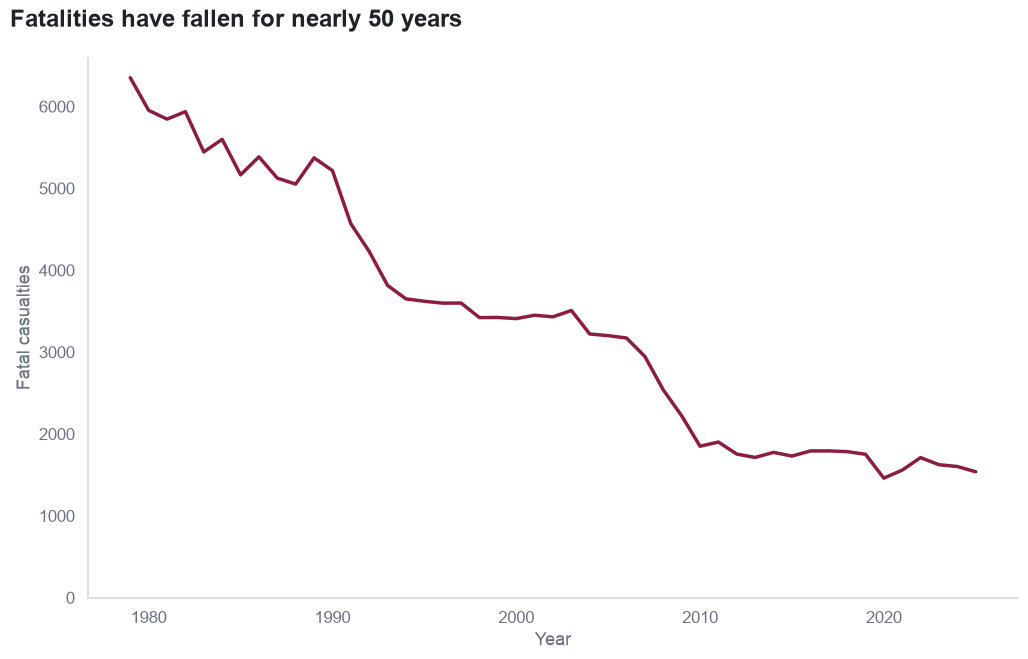

In [3]:
fig, ax = plt.subplots(figsize=VIDEO_FIG)
sns.lineplot(data=fatal_by_year, x="year", y="casualties", color=EXPOSED_COLOUR, ax=ax, linewidth=2.5)
headline(fig, "Fatalities have fallen for nearly 50 years")
ax.set_xlabel("Year")
ax.set_ylabel("Fatal casualties")
ax.set_ylim(0, None)
sns.despine()
save(fig, "01_historical_trend.png")
plt.show()

**What this shows:** one line — how many people died on Britain's roads, each year from 1979 to 2025.

**What it means:** in 1979, 6,352 people died. By 2025, that was down to 1,538 — a **76% drop**. On its own, that looks like a finished success story. Let's hold that thought — the rest of this notebook tests whether it's true for *everyone*, not just on average.

**One quick check first:** 2020 should show a dip, since COVID lockdowns emptied the roads that year.

In [4]:
fatal_by_year.set_index("year").loc[2017:2023]

,casualties
year,
2017,1793
2018,1784
2019,1752
2020,1460
2021,1558
2022,1711
2023,1624


**Confirmed:** deaths were steady at about 1,750–1,790 a year in 2017–2019, fell sharply to **1,460 in 2020** (a real one-off, down 17%, because people simply weren't travelling), then bounced back to 1,558 and 1,711. A genuine, explainable blip — safe to move on.

---
# Step 2 — The twist

## Chart 2: Did that improvement reach everyone equally?

That one line is a national average. Averages can hide two different stories. Let's split it: people with nothing protecting them in a crash — pedestrians, cyclists, motorcyclists — we'll call **"exposed"**. Everyone inside a vehicle, we'll call **"protected"**. We draw their death rates as two separate lines, using the same colours as before (dark red for exposed, grey for protected) so it still feels like one story.

**First, a quick check:** does the "what kind of road user" field actually have good data going all the way back to 1979?

In [5]:
usecols_check = ["collision_year", "casualty_type"]
check_chunks = []
for chunk in pd.read_csv(CASUALTY_FULL, usecols=usecols_check, chunksize=500_000, low_memory=False):
    check_chunks.append(chunk)
type_check = pd.concat(check_chunks)
type_check["decade"] = (type_check["collision_year"] // 10) * 10
missing_rate = type_check.groupby("decade")["casualty_type"].apply(lambda s: (s.isna() | (s == -1)).mean())
print("Missing/-1 casualty_type by decade:")
print(missing_rate.round(4))
del type_check, check_chunks

Missing/-1 casualty_type by decade:
decade
1970    0.000
1980    0.000
1990    0.000
2000    0.000
2010    0.000
2020    0.008
Name: casualty_type, dtype: float64


**Good news:** almost 0% missing data from the 1970s through the 2010s, only rising to a still-small 0.8% in the 2020s. We can trust this chart across the full 47 years.

In [6]:
EXPOSED_CODES = {0, 1, 2, 3, 4, 5, 23, 97}  # pedestrian, cyclist, motorcyclist variants

usecols2 = ["collision_year", "casualty_severity", "casualty_type"]
chunks2 = []
for chunk in pd.read_csv(CASUALTY_FULL, usecols=usecols2, chunksize=500_000, low_memory=False):
    chunk["group"] = chunk["casualty_type"].isin(EXPOSED_CODES).map({True: "Exposed", False: "Protected"})
    chunks2.append(
        chunk.groupby(["collision_year", "group", "casualty_severity"]).size().reset_index(name="n")
    )
gap_data = pd.concat(chunks2).groupby(["collision_year", "group", "casualty_severity"], as_index=False)["n"].sum()

fatal_share = (
    gap_data.groupby(["collision_year", "group"], group_keys=False)
    .apply(lambda g: g.loc[g["casualty_severity"] == 1, "n"].sum() / g["n"].sum(), include_groups=False)
    .rename("fatal_share")
    .reset_index()
)
fatal_share.to_csv(PROCESSED / "historical_severity_gap.csv", index=False)

gap_wide = fatal_share.pivot(index="collision_year", columns="group", values="fatal_share")
gap_wide["gap"] = gap_wide["Exposed"] - gap_wide["Protected"]
gap_wide["ratio"] = gap_wide["Exposed"] / gap_wide["Protected"]
gap_wide["decade"] = (gap_wide.index // 10) * 10
decade_ratio = gap_wide.groupby("decade")["ratio"].mean().round(2)
print("Gap in first 5 years avg:", gap_wide["gap"].iloc[:5].mean().round(4))
print("Gap in last 5 years avg:", gap_wide["gap"].iloc[-5:].mean().round(4))
print("\nRatio (exposed / protected) by decade:")
print(decade_ratio)

Gap in first 5 years avg: 0.0073
Gap in last 5 years avg: 0.0062

Ratio (exposed / protected) by decade:
decade
1970    1.51
1980    1.51
1990    1.71
2000    1.79
2010    1.98
2020    1.66
Name: ratio, dtype: float64


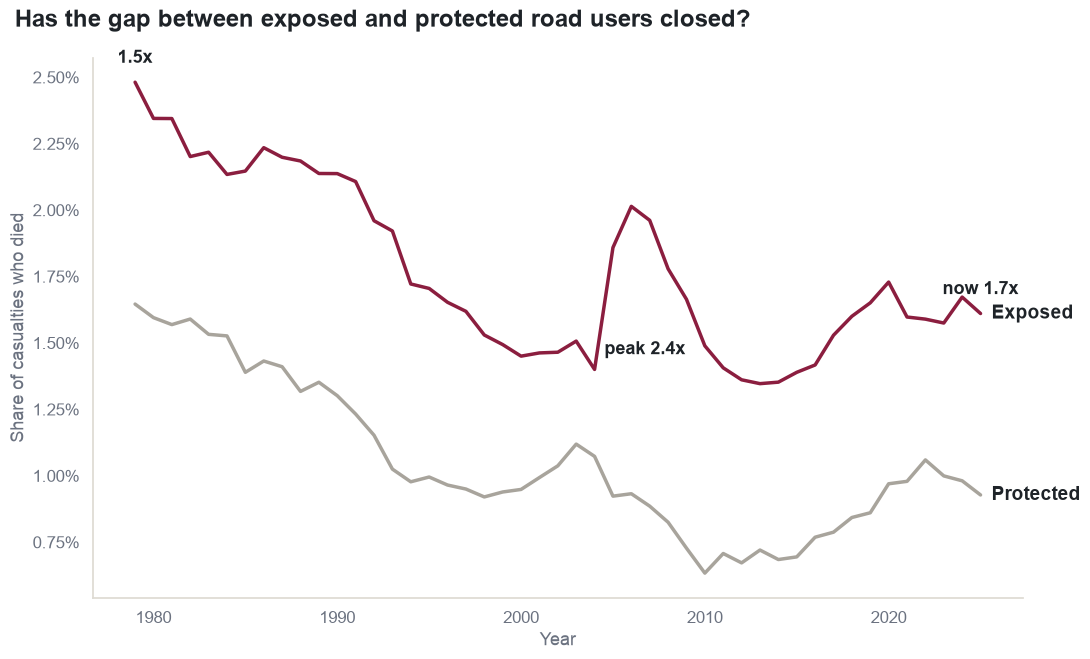

In [7]:
peak_year = gap_wide["ratio"].idxmax()
peak_ratio = gap_wide["ratio"].max()
start_ratio = gap_wide["ratio"].iloc[0]
end_ratio = gap_wide["ratio"].iloc[-1]

fig, ax = plt.subplots(figsize=VIDEO_FIG)
sns.lineplot(
    data=fatal_share, x="collision_year", y="fatal_share", hue="group",
    palette={"Exposed": EXPOSED_COLOUR, "Protected": PROTECTED_COLOUR}, ax=ax, linewidth=2.5, legend=False,
)
headline(fig, "Has the gap between exposed and protected road users closed?")
ax.set_xlabel("Year")
ax.set_ylabel("Share of casualties who died")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.2%}")

# Direct on-chart callouts, so the "twist" reads without narration
start_y = fatal_share.query("collision_year == collision_year.min() and group == 'Exposed'")["fatal_share"].iloc[0]
peak_y = fatal_share.query("collision_year == @peak_year and group == 'Exposed'")["fatal_share"].iloc[0]
end_y = fatal_share.query("collision_year == collision_year.max() and group == 'Exposed'")["fatal_share"].iloc[0]

ax.annotate(f"{start_ratio:.1f}x", xy=(fatal_share['collision_year'].min(), start_y),
            xytext=(0, 14), textcoords="offset points", ha="center", fontsize=13, fontweight="bold")
ax.annotate(f"peak {peak_ratio:.1f}x", xy=(peak_year, peak_y),
            xytext=(-14, -6), textcoords="offset points", ha="right", fontsize=13, fontweight="bold")
ax.annotate(f"now {end_ratio:.1f}x", xy=(fatal_share['collision_year'].max(), end_y),
            xytext=(0, 14), textcoords="offset points", ha="center", fontsize=13, fontweight="bold")

for group in ["Exposed", "Protected"]:
    ax.text(gap_wide.index.max() + 0.6, gap_wide[group].iloc[-1], group, va="center", fontsize=14, fontweight="bold")

sns.despine()
save(fig, "02_severity_gap.png")
plt.show()

**What this shows:** the same "chance of dying once hurt" measure as chart 1, but as two lines — exposed road users and protected ones.

**What it means:** both lines fall, but the gap between them never closes. By decade, an exposed casualty was this many times more likely to die than a protected one, in the same year:

- **1980s:** about **1.5×**
- **2000s–2010s:** widened to roughly **2.3×** — the worst point in 47 years
- **Now (2020s):** back down a bit, but still about **1.7×** — *higher than when records began*

So has the gap closed? **No.** Deaths fell a lot for both groups — that part is real — but exposed road users never caught up. Chart 1's single average line hid this completely.

---
# Step 3 — Why does that gap exist?

**The obvious guess:** exposed road users are probably out on faster, darker, more rural roads more often — so that's why they fare worse. Reasonable guess. Let's actually test it with the last 5 years of data, instead of assuming it's true.

First we join the crash, vehicle, and person tables together.

In [8]:
collisions = clean_columns(pd.read_csv(DATA / "collision_last_5_years.csv", low_memory=False))
vehicles = clean_columns(pd.read_csv(DATA / "vehicle_last_5_years.csv", low_memory=False))
casualties = clean_columns(pd.read_csv(DATA / "casualty_last_5_years.csv", low_memory=False))

joined = (
    casualties
    .merge(vehicles, on=["collision_index", "vehicle_reference"], how="left")
    .merge(collisions, on="collision_index", how="left")
)
assert len(joined) == len(casualties), "Join changed row count!"
print("Joined shape:", joined.shape, "| casualties:", len(casualties))

joined["severity"] = joined["casualty_severity"].map({1: "Fatal", 2: "Serious", 3: "Slight"})
joined["ksi"] = joined["casualty_severity"].isin([1, 2]).astype(int)


def road_user(code_):
    if code_ == 0:
        return "Pedestrian"
    if code_ == 1:
        return "Cyclist"
    if code_ in [2, 3, 4, 5, 23, 97]:
        return "Motorcyclist"
    if code_ == 9:
        return "Car occupant"
    return "Other"


joined["road_user"] = joined["casualty_type"].apply(road_user)
joined["urban_rural"] = joined["urban_or_rural_area"].map({1: "Urban", 2: "Rural"})
joined["day_night"] = joined["light_conditions"].apply(lambda x: "Daylight" if x == 1 else "Dark")
joined["exposure"] = joined["road_user"].isin(["Pedestrian", "Cyclist", "Motorcyclist"]).map(
    {True: "Exposed", False: "Protected"}
)

Joined shape: (652821, 96) | casualties: 652821


**Confirmed:** the join kept every one of the 652,821 casualties from 2021–2025 — nothing lost, nothing duplicated.

Before anything else, let's set a baseline: out of everyone hurt, how bad does it usually get?

  severity  casualties      share
0   Slight      515777  79.007416
1  Serious      129011  19.762079
2    Fatal        8033   1.230506


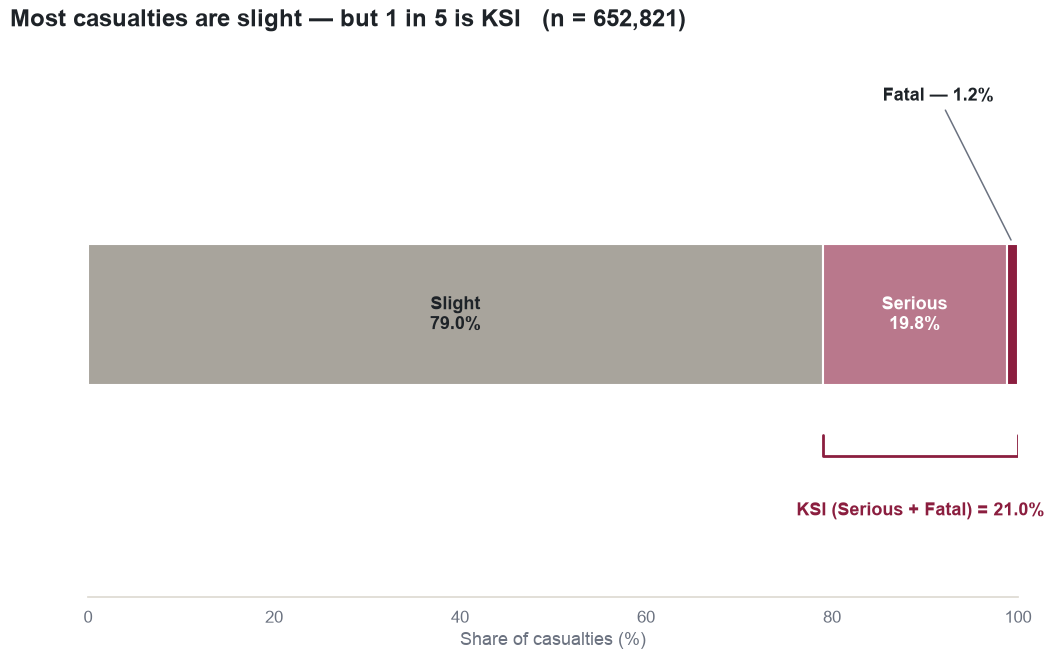

In [9]:
counts = joined["severity"].value_counts().reindex(["Slight", "Serious", "Fatal"]).reset_index()
counts.columns = ["severity", "casualties"]
counts["share"] = 100 * counts["casualties"] / counts["casualties"].sum()
print(counts)

fig, ax = plt.subplots(figsize=VIDEO_FIG)

left = 0
for row in counts.itertuples():
    ax.barh(0, row.share, left=left, height=0.55, color=SEVERITY_COLOURS[row.severity],
            edgecolor="white", linewidth=1.5)
    if row.share >= 5:
        text_colour = INK if row.severity == "Slight" else "white"
        ax.text(left + row.share / 2, 0, f"{row.severity}\n{row.share:.1f}%", ha="center", va="center",
                fontsize=13, fontweight="bold", color=text_colour)
    left += row.share

# Fatal is too thin for an inside label -- point to it from outside instead
fatal_share = counts.loc[counts["severity"] == "Fatal", "share"].iloc[0]
fatal_centre = 100 - fatal_share / 2
ax.annotate(
    f"Fatal — {fatal_share:.1f}%",
    xy=(fatal_centre, 0.28), xytext=(fatal_centre - 2, 0.85),
    ha="right", va="center", fontsize=13, fontweight="bold",
    arrowprops=dict(arrowstyle="-", color=MUTED, lw=1.1),
)

# bracket grouping Serious + Fatal as KSI
serious_share = counts.loc[counts["severity"] == "Serious", "share"].iloc[0]
ksi_share = serious_share + fatal_share
ksi_start = 100 - ksi_share
bracket_y = -0.55
ax.plot([ksi_start, ksi_start, 100, 100], [bracket_y + 0.08, bracket_y, bracket_y, bracket_y + 0.08],
        color=KSI_COLOUR, linewidth=2)
ax.text((ksi_start + 100) / 2, bracket_y - 0.18, f"KSI (Serious + Fatal) = {ksi_share:.1f}%",
        ha="center", va="top", fontsize=13, fontweight="bold", color=KSI_COLOUR)

ax.set_xlim(0, 100)
ax.set_ylim(-1.1, 1.0)
ax.set_yticks([])
ax.set_xlabel("Share of casualties (%)")
headline(fig, f"Most casualties are slight — but 1 in 5 is KSI   (n = {len(joined):,})")
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
sns.despine(left=True)
save(fig, "03_baseline.png")
plt.show()

**What this shows:** out of everyone hurt recently, how many walked away with a minor injury vs. a serious one vs. died.

**What it means:** most injuries (79.0%) are minor. But **1 in 5** (21.0%, Serious + Fatal combined = KSI) is serious or worse. This is the baseline every "per 1,000" number elsewhere in this notebook is measured against.

Now, back to the real question: why are exposed road users hurt worse? Let's test the obvious guess — out of each group's casualties, how many happened on a fast road, in the dark, or in the countryside?

In [10]:
tmp = joined.dropna(subset=["speed_limit", "day_night", "urban_rural"])
condition_rates = tmp.assign(
    fast=tmp["speed_limit"] >= 50, dark=tmp["day_night"] == "Dark", rural=tmp["urban_rural"] == "Rural",
).groupby("exposure")[["fast", "dark", "rural"]].mean() * 100
condition_rates.round(1)

,fast,dark,rural
exposure,,,
Exposed,9.9,25.6,19.6
Protected,35.9,31.0,47.3


**The obvious guess is wrong.** Exposed road users are actually hurt *less* often on fast roads (9.9% vs 35.9% for protected occupants) and *less* often in the countryside (19.6% vs 47.3%). Makes sense really — pedestrians and cyclists mostly stick to ordinary streets, while cars and vans cover more motorway and rural miles. So exposed road users are not unluckily stuck in worse conditions — the opposite is true.

**So where does the 1.5×–2.3× gap come from?** Let's compare exposed vs. protected KSI rate *within the exact same conditions* — same speed, same lighting, same area — so only the protection changes.

In [11]:
def label_row(row):
    speed = "Fast road" if row["speed_limit"] >= 50 else "Slower road"
    return f"{row['exposure']} | {speed} | {row['day_night']} | {row['urban_rural']}"


joined["combo_label"] = joined.apply(label_row, axis=1)

combo = (
    joined.dropna(subset=["road_user", "speed_limit", "day_night", "urban_rural"])
    .groupby("combo_label")
    .agg(casualties=("ksi", "size"), ksi=("ksi", "sum"))
    .reset_index()
)
combo = combo[combo["casualties"] >= 200]
combo["ksi_per_1000"] = 1000 * combo["ksi"] / combo["casualties"]
combo.to_csv(PROCESSED / "severity_combinations.csv", index=False)

split_labels = combo["combo_label"].str.split(" | ", regex=False, expand=True)
split_labels.columns = ["exposure", "speed_cat", "light_cat", "area_cat"]
combo_full = pd.concat([combo, split_labels], axis=1)

env_compare = combo_full.pivot_table(
    index=["speed_cat", "light_cat", "area_cat"], columns="exposure", values="ksi_per_1000"
)
env_compare["ratio"] = env_compare["Exposed"] / env_compare["Protected"]
print(env_compare.round(1))
print()
print("Ratio range across all 8 matched environments:",
      f"{env_compare['ratio'].min():.2f}x - {env_compare['ratio'].max():.2f}x",
      f"(average {env_compare['ratio'].mean():.2f}x)")

exposure                        Exposed  Protected  ratio
speed_cat   light_cat area_cat                           
Fast road   Dark      Rural       568.6      243.6    2.3
                      Urban       465.3      165.7    2.8
            Daylight  Rural       536.4      189.3    2.8
                      Urban       377.2      115.9    3.3
Slower road Dark      Rural       409.1      198.5    2.1
                      Urban       302.2      142.4    2.1
            Daylight  Rural       341.8      136.7    2.5
                      Urban       252.0      105.4    2.4

Ratio range across all 8 matched environments: 2.06x - 3.25x (average 2.54x)


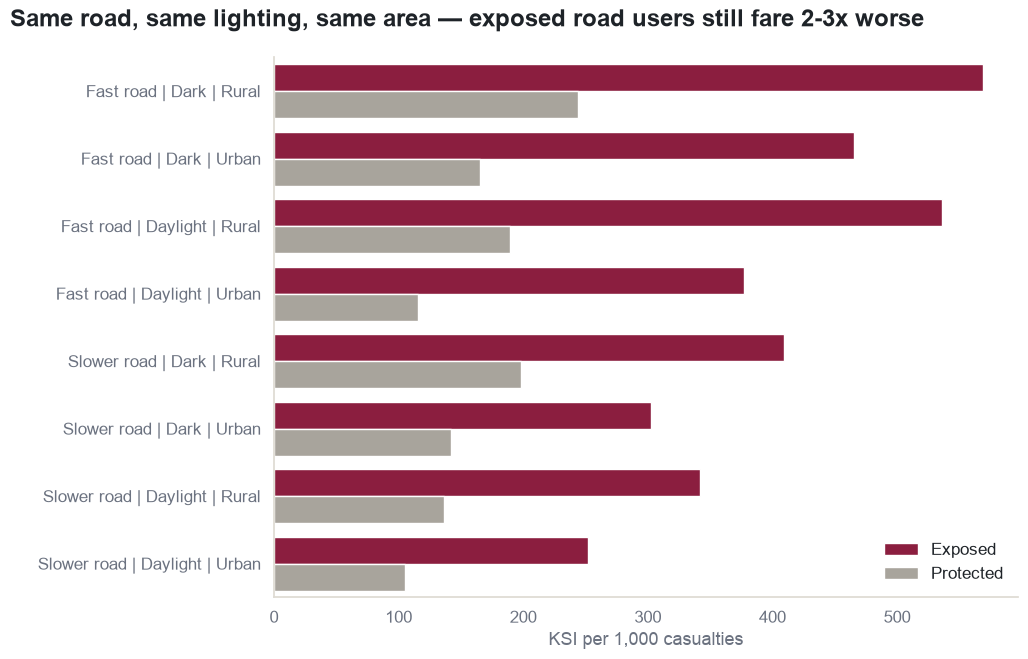

In [12]:
env_plot = combo_full.copy()
env_plot["environment"] = env_plot["speed_cat"] + " | " + env_plot["light_cat"] + " | " + env_plot["area_cat"]
env_plot = env_plot.sort_values(["speed_cat", "light_cat", "area_cat"])

fig, ax = plt.subplots(figsize=VIDEO_FIG)
sns.barplot(
    data=env_plot, y="environment", x="ksi_per_1000", hue="exposure",
    palette={"Exposed": EXPOSED_COLOUR, "Protected": PROTECTED_COLOUR}, ax=ax, saturation=1,
)
headline(fig, "Same road, same lighting, same area — exposed road users still fare 2-3x worse")
ax.set_xlabel("KSI per 1,000 casualties")
ax.set_ylabel(None)
ax.legend(title=None, frameon=False)
sns.despine()
fig.subplots_adjust(left=0.28)
save(fig, "02b_matched_conditions.png")
plt.show()

**What this shows:** exposed vs. protected KSI rate, measured again for every combination of fast/slow road, light/dark, city/countryside — so it's always "same road, same time of day, same area."

**What it means:** exposed road users come off worse in *every single one* of the eight match-ups — by roughly 2 to 3 times each time (2.1× to 3.3×, even 2.4× in the safest conditions tested). So the gap isn't about worse roads — it's simply riskier to have nothing protecting you, no matter the road. That's the real reason behind the gap in chart 2.

**A closer look at the same eight match-ups.** Long labels make it hard to see which conditions changed from one row to the next. So here each environment becomes a column, ordered from the smallest multiple to the largest. The dots underneath say which conditions apply to each one.

> **Side note: why a log scale?** In this chart, take two of the lines:
>
> - First: 105 to 252, which is about ×2.4
> - Second: 244 to 569, which is about ×2.3
>
> On a normal ruler, the second line would look more than twice as long, because it covers more points. That would suggest the gap gets much worse on risky roads. On the log ruler they're almost the same length, which is correct, because both are "a bit more than double".
>
> **To read it:** the dots are still the real numbers, and a longer line means a bigger multiple.

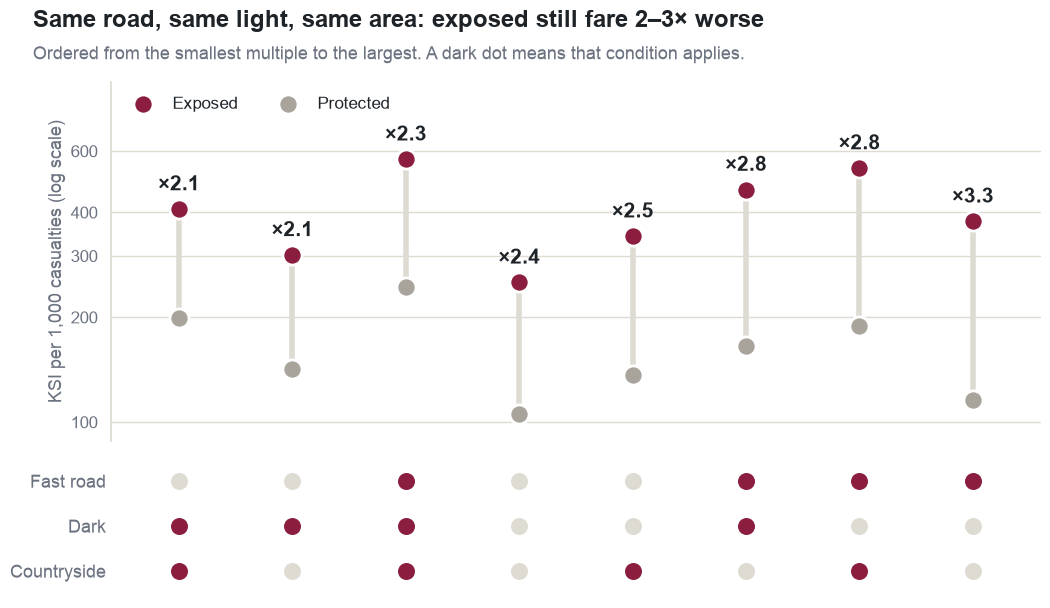

In [13]:
env_matrix = env_compare.reset_index().sort_values("ratio").reset_index(drop=True)
env_matrix["fast"] = env_matrix["speed_cat"] == "Fast road"
env_matrix["dark"] = env_matrix["light_cat"] == "Dark"
env_matrix["rural"] = env_matrix["area_cat"] == "Rural"
x = env_matrix.index.to_numpy()

fig, (ax, ax_grid) = plt.subplots(2, 1, figsize=VIDEO_FIG, sharex=True,
                                  gridspec_kw={"height_ratios": [3, 1.2], "hspace": 0.05})

# log scale: the same gap always means the same multiplier
ax.set_yscale("log")
ax.vlines(x, env_matrix["Protected"], env_matrix["Exposed"], color=RULE, linewidth=4, zorder=1)
ax.scatter(x, env_matrix["Protected"], s=190, color=PROTECTED_COLOUR, edgecolor="white", linewidth=2, zorder=2, label="Protected")
ax.scatter(x, env_matrix["Exposed"], s=190, color=EXPOSED_COLOUR, edgecolor="white", linewidth=2, zorder=2, label="Exposed")
for row in env_matrix.itertuples():
    ax.text(row.Index, row.Exposed * 1.1, f"×{row.ratio:.1f}", ha="center", va="bottom", fontsize=15, fontweight="bold")
ax.set_ylim(88, 950)
ax.set_yticks([100, 200, 300, 400, 600])
ax.set_yticklabels(["100", "200", "300", "400", "600"])
ax.minorticks_off()
ax.set_ylabel("KSI per 1,000 casualties (log scale)")
ax.grid(axis="y", color=RULE, linewidth=1)
ax.set_axisbelow(True)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left", frameon=False, ncol=2)
sns.despine(ax=ax, bottom=True)
ax.tick_params(axis="x", length=0)

factors = [("Fast road", "fast"), ("Dark", "dark"), ("Countryside", "rural")]
for y, (_, column) in zip([4, 3, 2], factors):
    on = env_matrix[column].to_numpy()
    ax_grid.scatter(x[~on], [y] * (~on).sum(), s=150, color=RULE, linewidth=0)
    ax_grid.scatter(x[on], [y] * on.sum(), s=150, color=HARM, linewidth=0)
ax_grid.set_yticks([4, 3, 2], [f[0] for f in factors])
ax_grid.set_ylim(1.4, 4.6)
ax_grid.set_xlim(-0.6, x.max() + 0.6)
ax_grid.set_xticks([])
ax_grid.tick_params(axis="y", length=0, labelsize=13)
sns.despine(ax=ax_grid, left=True, bottom=True)

headline(fig, "Same road, same light, same area: exposed still fare 2–3× worse",
         "Ordered from the smallest multiple to the largest. A dark dot means that condition applies.")
save(fig, "02b_matched_conditions_matrix.png")
plt.show()

**What this shows:** the same eight match-ups, ordered from the smallest multiple on the left to the largest on the right.

**What it means:** even the smallest multiple is ×2.1, so exposed road users fare at least twice as badly in every environment, including the safest one (252 vs 105 per 1,000). The three largest multiples (×2.8 to ×3.3) are all on fast roads. Safer conditions help both groups, but they don't close the gap.

---
# Step 3b — Do risky conditions add to that gap?

We now know exposed road users are more at risk, on any road. But does the road itself still matter on top of that? Four real situations, safest to worst:

1. **Protected, slow road, daylight, city** — the safest setup.
2. **Protected, fast road, dark, countryside** — swap in the riskiest road.
3. **Exposed, slow road, daylight, city** — keep the safe road, swap out the protection instead.
4. **Exposed, fast road, dark, countryside** — both at once.

In [14]:
combo = combo.sort_values("ksi_per_1000")
combo

,combo_label,casualties,ksi,ksi_per_1000
15,Protected | Slower road | Daylight | Urban,134173,14139,105.378877
11,Protected | Fast road | Daylight | Urban,8928,1035,115.927419
14,Protected | Slower road | Daylight | Rural,42080,5751,136.668251
13,Protected | Slower road | Dark | Urban,62999,8971,142.399086
9,Protected | Fast road | Dark | Urban,4527,750,165.672631
10,Protected | Fast road | Daylight | Rural,90536,17140,189.316957
12,Protected | Slower road | Dark | Rural,16739,3322,198.458689
8,Protected | Fast road | Dark | Rural,39491,9620,243.599808
7,Exposed | Slower road | Daylight | Urban,146483,36910,251.974632
5,Exposed | Slower road | Dark | Urban,54706,16531,302.178920


Every combination already shows a wide spread — from about 105 to 569 per 1,000. Now the four chosen situations, side by side:

{'Protected': (np.float64(105.37887652508329), np.float64(243.5998075510876)), 'Exposed': (np.float64(251.97463186854446), np.float64(568.5898970553028))}


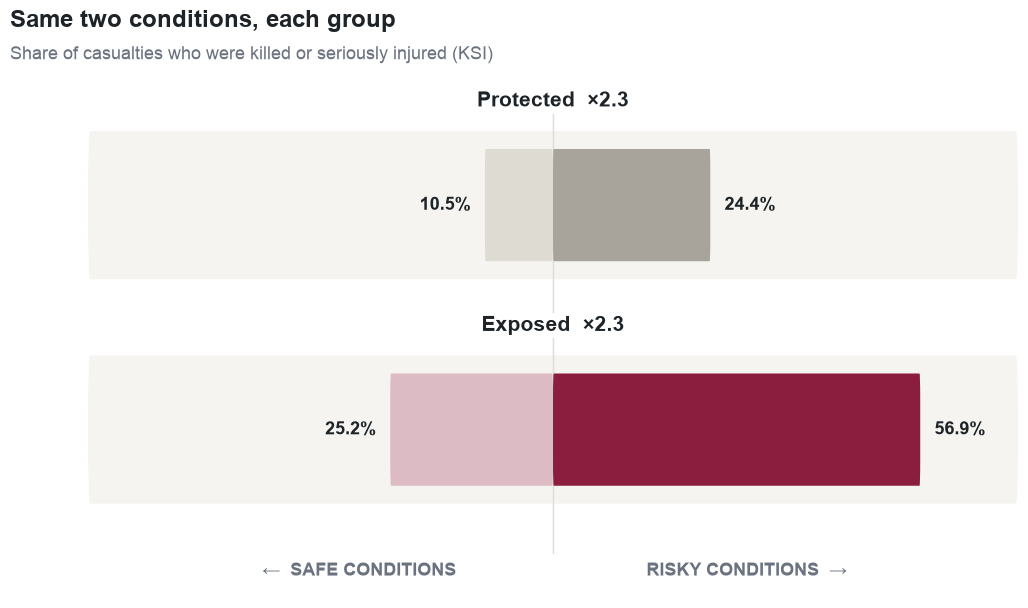

Lowest combo rate: 105.4 per 1000, highest: 568.6 per 1000, ratio: 5.40x


In [15]:
from matplotlib.patches import FancyBboxPatch

# same two environments for both groups, so the comparison is apples-to-apples:
# "safe" = slower road, daylight, urban | "risky" = fast road, dark, rural
safe_label = "{group} | Slower road | Daylight | Urban"
risky_label = "{group} | Fast road | Dark | Rural"

rates = {}
for group in ["Protected", "Exposed"]:
    rates[group] = (
        combo.loc[combo["combo_label"] == safe_label.format(group=group), "ksi_per_1000"].iloc[0],
        combo.loc[combo["combo_label"] == risky_label.format(group=group), "ksi_per_1000"].iloc[0],
    )
print(rates)

GROUP_STYLE = {
    "Protected": dict(risky=PROTECTED_COLOUR, safe=RULE),
    "Exposed": dict(risky=EXPOSED_COLOUR, safe=HARM_LIGHT),
}


def rounded_bar(ax, y, x0, x1, colour, height=0.5):
    width = abs(x1 - x0)
    left = min(x0, x1)
    box = FancyBboxPatch(
        (left, y - height / 2), max(width, 0.01), height,
        boxstyle=f"round,pad=0,rounding_size={height * 0.22}",
        linewidth=0, facecolor=colour, zorder=3,
    )
    ax.add_patch(box)


fig, ax = plt.subplots(figsize=VIDEO_FIG)
y_pos = [1, 0]

for group, y in zip(["Protected", "Exposed"], y_pos):
    safe_v, risky_v = rates[group]
    safe_pct, risky_pct = safe_v / 10, risky_v / 10  # per-1,000 -> %
    style = GROUP_STYLE[group]

    ax.add_patch(FancyBboxPatch((-72, y - 0.33), 144, 0.66, boxstyle="round,pad=0,rounding_size=0.33",
                                 linewidth=0, facecolor="#F5F4F1", zorder=1))

    rounded_bar(ax, y, 0, -safe_pct, style["safe"])
    rounded_bar(ax, y, 0, risky_pct, style["risky"])

    ax.text(-safe_pct - 2.2, y, f"{safe_pct:.1f}%", ha="right", va="center",
            fontsize=13, fontweight="bold", color="#1E2328", zorder=4)
    ax.text(risky_pct + 2.2, y, f"{risky_pct:.1f}%", ha="left", va="center",
            fontsize=13, fontweight="bold", color="#1E2328", zorder=4)

    mult = risky_pct / safe_pct
    ax.text(0, y + 0.42, f"{group}  \u00d7{mult:.1f}", ha="center", va="bottom", fontsize=15,
            fontweight="bold", zorder=4, bbox=dict(facecolor="white", edgecolor="none", pad=2))

ax.plot([0, 0], [-0.55, 1.5], color=RULE, linewidth=1, zorder=2)
ax.set_yticks([])
ax.set_xticks([])
ax.set_xlim(-72, 72)
ax.set_ylim(-0.75, 1.55)
for spine in ax.spines.values():
    spine.set_visible(False)

ax.text(-30, -0.65, "\u2190  SAFE CONDITIONS", ha="center", fontsize=13, color=MUTED,
        fontweight="bold")
ax.text(30, -0.65, "RISKY CONDITIONS  \u2192", ha="center", fontsize=13, color=MUTED,
        fontweight="bold")

headline(fig, "Same two conditions, each group", "Share of casualties who were killed or seriously injured (KSI)")
save(fig, "06_stacking.png")
plt.show()

lowest = min(v for pair in rates.values() for v in pair)
highest = max(v for pair in rates.values() for v in pair)
print(f"Lowest combo rate: {lowest:.1f} per 1000, highest: {highest:.1f} per 1000, ratio: {highest/lowest:.2f}x")

**What this shows:** the four situations above, from safest to worst.

**What it means:** the worst case is **over 5 times worse** than the best case (105 → 569 per 1,000, a 5.4× jump) — far more than losing protection or hitting a bad road would cause on its own. Here's why: swapping "protected" for "exposed" roughly multiplies the rate by **2–3×**. Separately, swapping the best road conditions for the worst roughly multiplies it by **2.3×** (protected: 105 → 244; exposed: 252 → 569 — almost the same step both times). Multiply those two together — about 2.4× × 2.3× — and you land almost exactly on the 5.4× we actually see. **The worst outcomes aren't one bad factor. They're two separate risks landing on the same person and multiplying.**

**A sharper test of the same four situations.** Put them at the corners of one shape. If risks simply *add up*, the worst corner should be the best corner plus both increases. If risks *multiply*, it should be the best corner times both multipliers. Only one of those can be right.

Worst case if risks added: 390 | if they multiplied: 582 | actual: 569


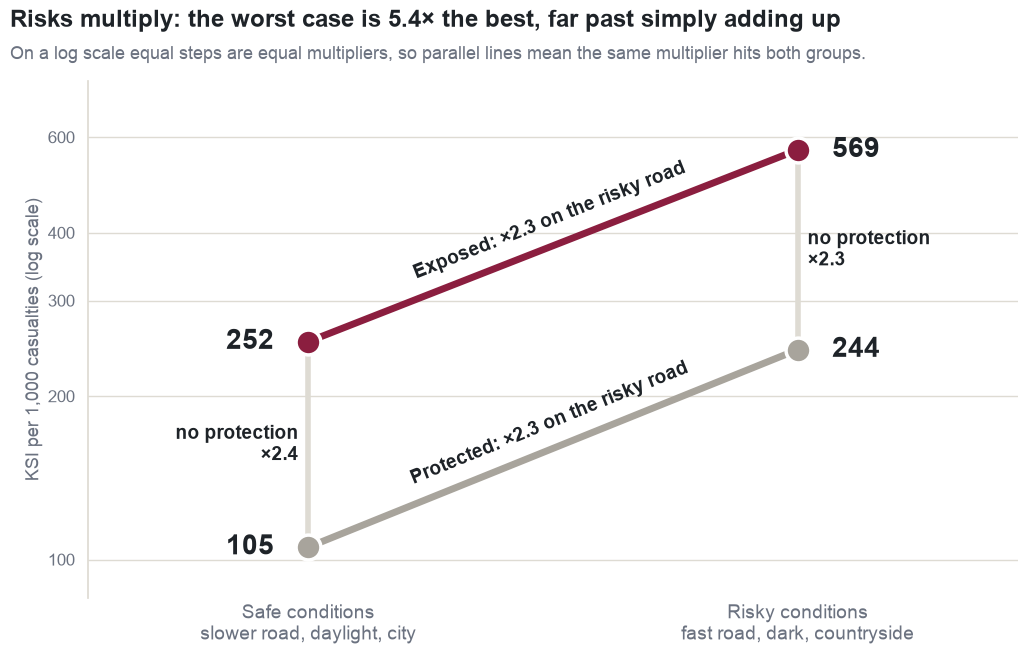

In [16]:
safe_p, risky_p = rates["Protected"]
safe_e, risky_e = rates["Exposed"]
if_added = risky_p + safe_e - safe_p
if_multiplied = risky_p * safe_e / safe_p
print(f"Worst case if risks added: {if_added:.0f} | if they multiplied: {if_multiplied:.0f} | actual: {risky_e:.0f}")

fig, ax = plt.subplots(figsize=VIDEO_FIG)
ax.set_yscale("log")
ax.set_xlim(-0.45, 1.45)
ax.set_ylim(85, 760)

ax.plot([0, 0], [safe_p, safe_e], color=RULE, linewidth=4, zorder=1)
ax.plot([1, 1], [risky_p, risky_e], color=RULE, linewidth=4, zorder=1)

for group, colour in [("Protected", PROTECTED_COLOUR), ("Exposed", EXPOSED_COLOUR)]:
    safe_v, risky_v = rates[group]
    ax.plot([0, 1], [safe_v, risky_v], color=colour, linewidth=5, solid_capstyle="round", zorder=2)
    ax.scatter([0, 1], [safe_v, risky_v], s=320, color=colour, edgecolor="white", linewidth=2.5, zorder=3)

    # lay the label along the line, whatever the axis scales do to its angle
    start, end = ax.transData.transform([(0, safe_v), (1, risky_v)])
    angle = np.degrees(np.arctan2(end[1] - start[1], end[0] - start[0]))
    ax.annotate(f"{group}: ×{risky_v / safe_v:.1f} on the risky road", (0.5, np.sqrt(safe_v * risky_v)), textcoords="offset points",
                xytext=(0, 12), ha="center", va="bottom", rotation=angle, rotation_mode="anchor", fontsize=14, fontweight="bold")

    ax.text(-0.07, safe_v, f"{safe_v:.0f}", ha="right", va="center", fontsize=20, fontweight="bold")

ax.text(-0.02, np.sqrt(safe_p * safe_e), f"no protection\n×{safe_e / safe_p:.1f}", ha="right", va="center", fontsize=14, fontweight="bold")
ax.text(1.02, np.sqrt(risky_p * risky_e), f"no protection\n×{risky_e / risky_p:.1f}", ha="left", va="center", fontsize=14, fontweight="bold")

ax.text(1.07, risky_p, f"{risky_p:.0f}", ha="left", va="center", fontsize=20, fontweight="bold")

ax.text(1.07, risky_e, f"{risky_e:.0f}", ha="left", va="center", fontsize=20, fontweight="bold")

ax.set_xticks([0, 1], ["Safe conditions\nslower road, daylight, city", "Risky conditions\nfast road, dark, countryside"], fontsize=14)
ax.set_yticks([100, 200, 300, 400, 600])
ax.set_yticklabels(["100", "200", "300", "400", "600"])
ax.minorticks_off()
ax.set_ylabel("KSI per 1,000 casualties (log scale)")
ax.grid(axis="y", color=RULE, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(axis="x", length=0)
sns.despine(bottom=True)
headline(fig, f"Risks multiply: the worst case is {risky_e / safe_p:.1f}× the best, far past simply adding up",
         "On a log scale equal steps are equal multipliers, so parallel lines mean the same multiplier hits both groups.")
save(fig, "06_stacking_parallelogram.png")
plt.show()

**What this shows:** the four situations as the corners of a parallelogram. The log scale turns each multiplier into a step of a fixed size, so if the same multipliers apply everywhere, the shape closes neatly.

**What it means:** if the two risks only added up, the worst case would be **390 per 1,000**. If they multiplied, it would be **582**. The real figure is **569**, so these risks multiply.

---
# A few more checks

Two quick checks that fill in the picture — not the main story, but good background. After these, step 4 picks the thread back up.

## Does speed limit matter on its own?

Before the "risks stack up" story, does speed limit alone matter? Two things to remember: this is the **posted** limit, not the actual speed driven, and different limits are used on very different kinds of roads (20mph = residential street, 70mph = motorway).

   speed_limit  casualties    ksi  ksi_per_1000
1           20       98837  17944    181.551443
2           30      324295  64388    198.547619
3           40       61137  12907    211.116018
4           50       33116   7571    228.620606
5           60       92367  26034    281.853909
6           70       43066   8199    190.382204


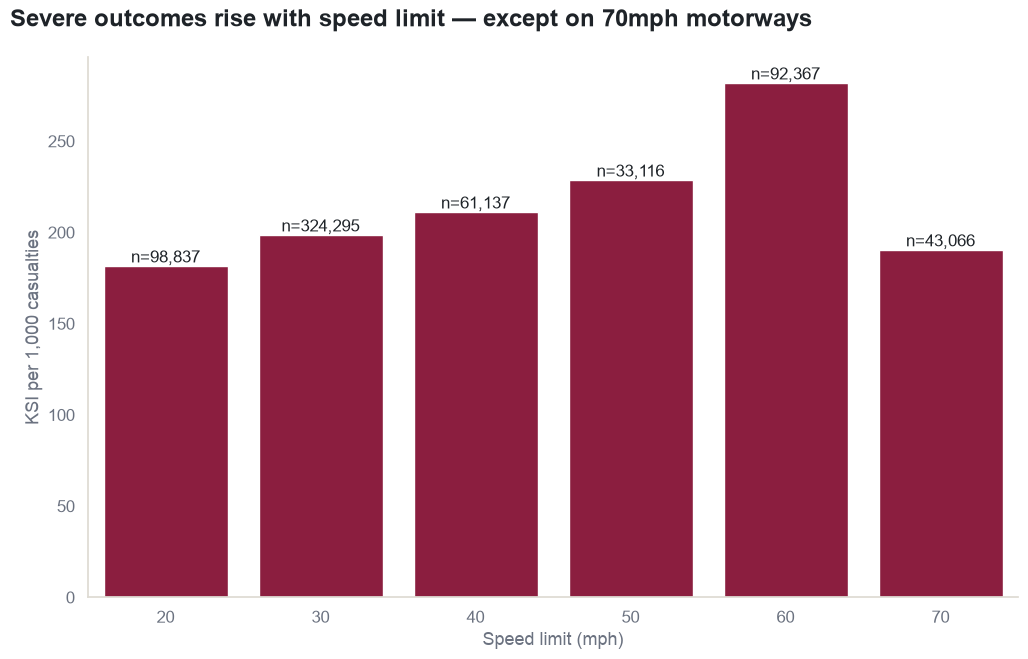

In [17]:
speed = (
    joined.dropna(subset=["speed_limit"])
    .groupby("speed_limit")
    .agg(casualties=("ksi", "size"), ksi=("ksi", "sum"))
    .reset_index()
)
speed = speed[speed["casualties"] >= 200]
speed["ksi_per_1000"] = 1000 * speed["ksi"] / speed["casualties"]
print(speed)

fig, ax = plt.subplots(figsize=VIDEO_FIG)
sns.barplot(data=speed, x="speed_limit", y="ksi_per_1000", color=KSI_COLOUR, ax=ax, saturation=1)
for i, row in speed.reset_index(drop=True).iterrows():
    ax.text(i, row["ksi_per_1000"] + 2, f"n={row['casualties']:,.0f}", ha="center", fontsize=12)
headline(fig, "Severe outcomes rise with speed limit — except on 70mph motorways")
ax.set_xlabel("Speed limit (mph)")
ax.set_ylabel("KSI per 1,000 casualties")
sns.despine()
save(fig, "04_speed.png")
plt.show()

**What this shows:** KSI rate at each posted speed limit, from 20mph streets to 70mph motorways.

**What it means:** severity rises steadily with speed limit, from 182 per 1,000 at 20mph up to 282 at 60mph — then **drops to 190 at 70mph**. Not a fluke (n=43,066 at 70mph) — those roads are almost all motorways, which are safer in other ways (no junctions, no pedestrians), even at a higher limit.

**Does that dip apply to everyone?** The bars above mix exposed and protected road users together, and almost everyone hurt on a 70mph road is inside a vehicle. So we split the two groups, and draw each point as the road sign for that limit.

     exposure  speed_limit  casualties    ksi  ksi_per_1000
0     Exposed           20       65135  14472    222.184693
1     Exposed           30      147907  42498    287.329200
2     Exposed           40       15213   6083    399.855387
3     Exposed           50        5716   2766    483.904829
4     Exposed           60       16182   8752    540.847856
5     Exposed           70        3151   1736    550.936211
6   Protected           20       33702   3472    103.020592
7   Protected           30      176388  21890    124.101413
8   Protected           40       45924   6824    148.593328
9   Protected           50       27400   4805    175.364964
10  Protected           60       76185  17282    226.842554
11  Protected           70       39915   6463    161.919078


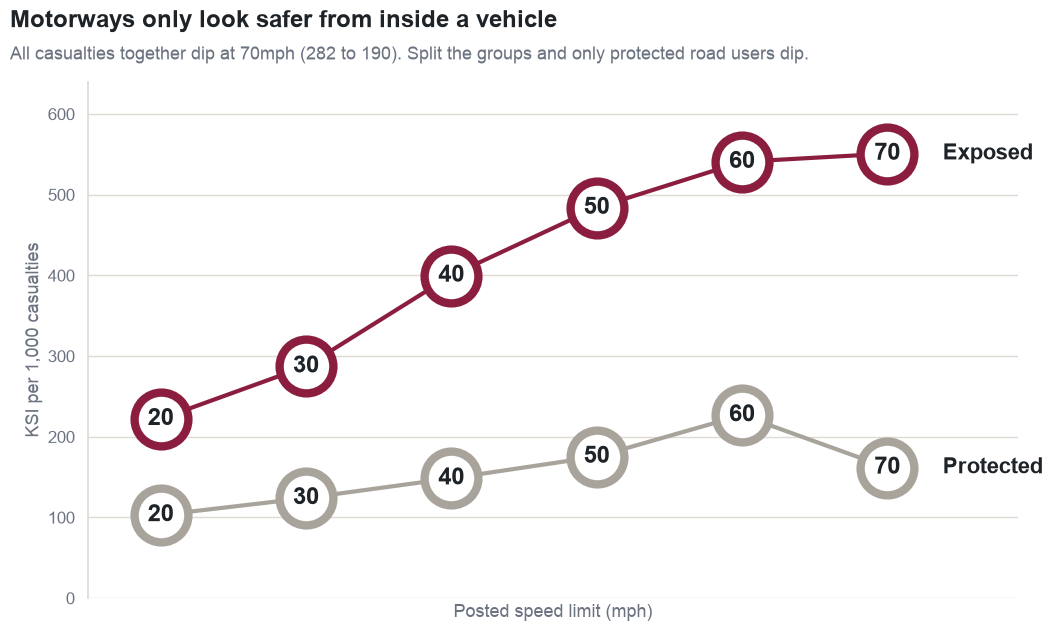

In [18]:
speed_split = (
    joined[joined["speed_limit"].isin(speed["speed_limit"])]
    .groupby(["exposure", "speed_limit"])
    .agg(casualties=("ksi", "size"), ksi=("ksi", "sum"))
    .reset_index()
)
speed_split = speed_split[speed_split["casualties"] >= 200]
speed_split["ksi_per_1000"] = 1000 * speed_split["ksi"] / speed_split["casualties"]
print(speed_split)

fig, ax = plt.subplots(figsize=VIDEO_FIG)
for group, colour in [("Exposed", EXPOSED_COLOUR), ("Protected", PROTECTED_COLOUR)]:
    rows = speed_split[speed_split["exposure"] == group]
    ax.plot(rows["speed_limit"], rows["ksi_per_1000"], color=colour, linewidth=3, zorder=1)
    # each marker is the road sign for that limit
    ax.scatter(rows["speed_limit"], rows["ksi_per_1000"], s=1500, facecolor="white", edgecolor=colour, linewidth=6, zorder=2)
    for row in rows.itertuples():
        ax.text(row.speed_limit, row.ksi_per_1000, f"{row.speed_limit:.0f}", ha="center", va="center",
                fontsize=17, fontweight="bold", zorder=3)
    last = rows.iloc[-1]
    ax.annotate(group, (last["speed_limit"], last["ksi_per_1000"]), textcoords="offset points", xytext=(40, 0),
                va="center", fontsize=16, fontweight="bold")

ax.set_xlim(15, 79)
ax.set_ylim(0, 640)
ax.set_xticks([])
ax.set_xlabel("Posted speed limit (mph)")
ax.set_ylabel("KSI per 1,000 casualties")
ax.grid(axis="y", color=RULE, linewidth=1)
ax.set_axisbelow(True)
sns.despine(bottom=True)
headline(fig, "Motorways only look safer from inside a vehicle",
         "All casualties together dip at 70mph (282 to 190). Split the groups and only protected road users dip.")
save(fig, "04_speed_signs.png")
plt.show()

**What this shows:** KSI rate at each posted speed limit, shown separately for exposed and protected road users.

**What it means:** the dip belongs to one group only. Protected casualties drop from 227 to 162 per 1,000. Exposed casualties don't dip at all, going from 541 to **551** (n=3,151). A motorway only protects people who are already protected, and the combined figure dips because 93% of 70mph casualties are inside a vehicle.

## Who ends up worse off, relative to their numbers?

Imagine 100 random casualties in a room. Now imagine a second room with only the 100 worst-hurt (KSI) casualties. Does the mix of people change? We use a pictogram — two grids of 100 squares — because seeing a colour take up more space is faster to read than comparing two dots. Road users with nothing protecting them are in shades of red, and everyone else is in grey.

      road_user  casualties    ksi  casualty_share  ksi_share     gap_pp
0  Car occupant      347393  51624        0.532141   0.376697 -15.544474
3         Other       52123   9113        0.079843   0.066497  -1.334582
1       Cyclist       77741  19503        0.119085   0.142312   2.322725
4    Pedestrian       94398  29092        0.144600   0.212282   6.768206
2  Motorcyclist       81166  27712        0.124331   0.202212   7.788126


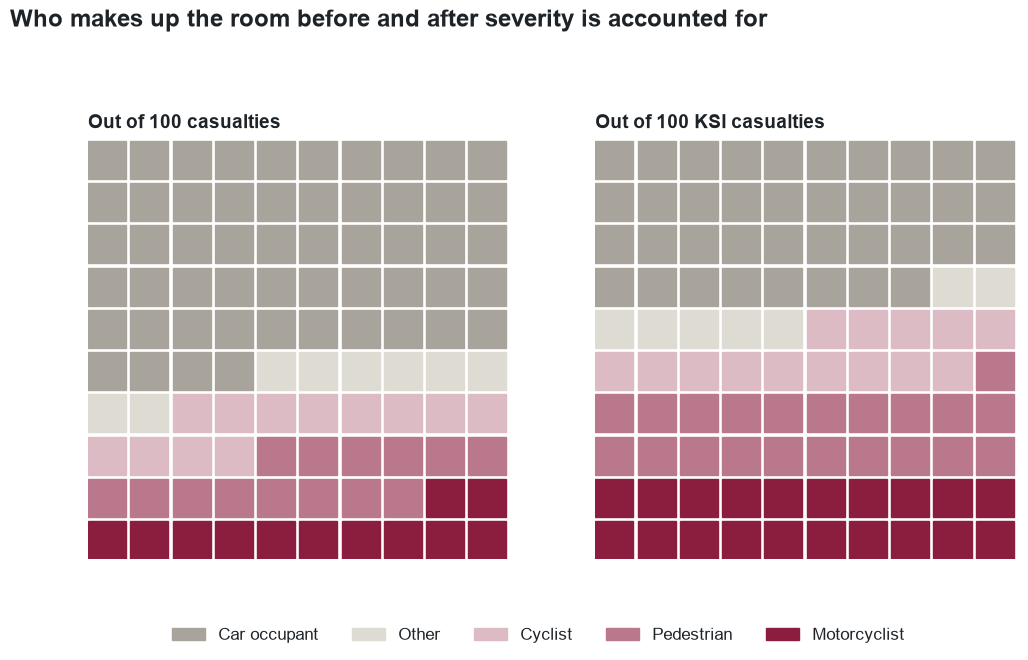

In [19]:
import numpy as np
import matplotlib.patches as mpatches

# road users without a shell share the red family, and sit together in each grid
ROAD_USER_COLOURS = {
    "Car occupant": NEUTRAL,
    "Other": RULE,
    "Cyclist": HARM_LIGHT,
    "Pedestrian": HARM_MID,
    "Motorcyclist": HARM,
}
ROAD_USER_ORDER = ["Car occupant", "Other", "Cyclist", "Pedestrian", "Motorcyclist"]

by_user = (
    joined.groupby("road_user")
    .agg(casualties=("ksi", "size"), ksi=("ksi", "sum"))
    .reset_index()
)
by_user = by_user[by_user["casualties"] >= 200]
by_user["casualty_share"] = by_user["casualties"] / by_user["casualties"].sum()
by_user["ksi_share"] = by_user["ksi"] / by_user["ksi"].sum()
by_user["gap_pp"] = 100 * (by_user["ksi_share"] - by_user["casualty_share"])
print(by_user.sort_values("gap_pp"))


def waffle_grid(shares, order, colours, ax, title):
    counts = {g: int(round(shares[g] * 100)) for g in order}
    counts[order[0]] += 100 - sum(counts.values())  # absorb rounding into the largest group
    seq = []
    for g in order:
        seq += [g] * counts[g]
    grid = np.array(seq[:100]).reshape(10, 10)
    for i in range(10):
        for j in range(10):
            ax.add_patch(plt.Rectangle((j, 9 - i), 0.9, 0.9, color=colours[grid[i, j]]))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)


cas_shares = dict(zip(by_user["road_user"], by_user["casualty_share"]))
ksi_shares = dict(zip(by_user["road_user"], by_user["ksi_share"]))

fig, axes = plt.subplots(1, 2, figsize=VIDEO_FIG)
waffle_grid(cas_shares, ROAD_USER_ORDER, ROAD_USER_COLOURS, axes[0], "Out of 100 casualties")
waffle_grid(ksi_shares, ROAD_USER_ORDER, ROAD_USER_COLOURS, axes[1], "Out of 100 KSI casualties")
handles = [mpatches.Patch(color=ROAD_USER_COLOURS[g], label=g) for g in ROAD_USER_ORDER]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 0.02))
headline(fig, "Who makes up the room before and after severity is accounted for")
fig.subplots_adjust(top=0.84, bottom=0.12)
save(fig, "05_protection_gap.png")
plt.show()

**What this shows:** car occupants are 53% of the first room but only 38% of the second (KSI) room. Pedestrians go from 14% to 21%. Motorcyclists go from 12% to 20%. Cyclists barely move, 12% to 14%.

**What it means:** car occupants shrink the most (−15.5 percentage points) — the car body is absorbing a lot of the impact for them. Motorcyclists (+7.8pp) and pedestrians (+6.8pp) grow the most — a crash is far more likely to turn out badly for them. This is the same "exposed vs. protected" gap from step 3, just made visible as a change in room size instead of a ratio.

---
# Step 4 — Does the same pattern show up elsewhere?

Step 3b found that risk compounds — two separate things (no protection, bad conditions) multiply together. But that was one split, on one 5-year slice. Is that really how this data behaves, or did we just get lucky with one variable?

We test the same idea on four more things: age, how rich or poor someone's area is, how powerful their vehicle is, and the time of day. If the same shape keeps showing up, that's good evidence it's a real pattern, not a coincidence.

**What we're checking:** does age change how badly a crash turns out, separate from how someone was travelling? For each age group, what share end up KSI?

   age_label  casualties  ksi_per_1000
0        0-5       10419    160.476053
1       6-10       16597    166.415617
2      11-15       30523    218.425450
3      16-20       68000    230.926471
4      21-25       70305    195.277719
5      26-35      132804    180.694859
6      36-45      100841    182.197717
7      46-55       81997    210.019879
8      56-65       64371    250.780631
9      66-75       33977    293.492657
10       75+       28881    336.345694


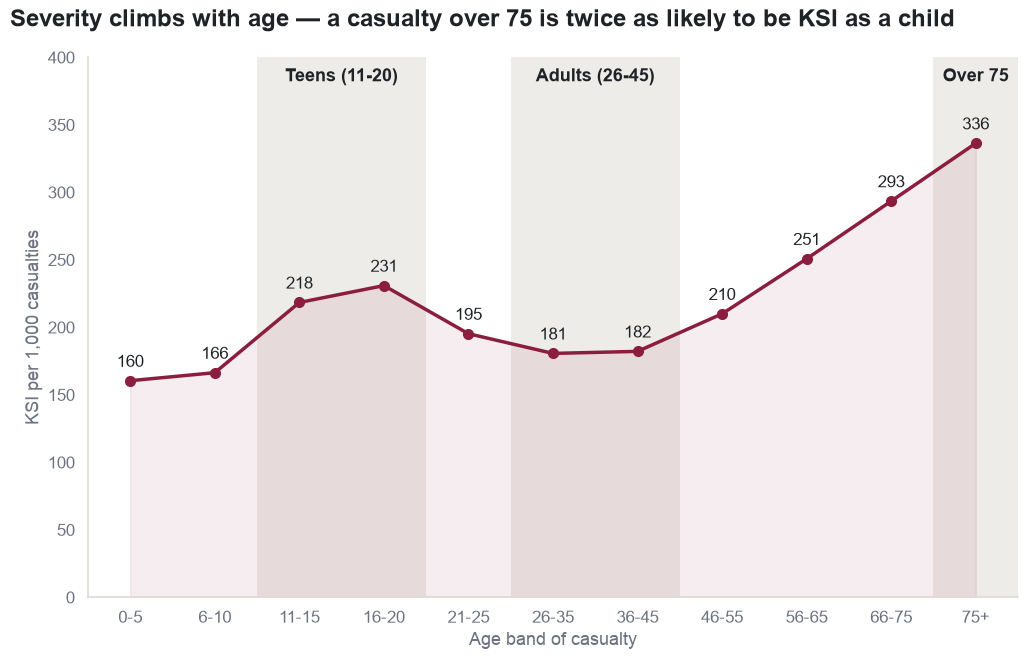

In [20]:
AGE_BAND_LABELS = {
    1: "0-5", 2: "6-10", 3: "11-15", 4: "16-20", 5: "21-25", 6: "26-35",
    7: "36-45", 8: "46-55", 9: "56-65", 10: "66-75", 11: "75+",
}

age = (
    joined[joined["age_band_of_casualty"].isin(AGE_BAND_LABELS)]
    .groupby("age_band_of_casualty")
    .agg(casualties=("ksi", "size"), ksi=("ksi", "sum"))
    .reset_index()
)
age["ksi_per_1000"] = 1000 * age["ksi"] / age["casualties"]
age["age_label"] = age["age_band_of_casualty"].map(AGE_BAND_LABELS)
age = age.sort_values("age_band_of_casualty")
print(age[["age_label", "casualties", "ksi_per_1000"]])

fig, ax = plt.subplots(figsize=VIDEO_FIG)
ax.plot(age["age_label"], age["ksi_per_1000"], color=KSI_COLOUR, linewidth=2.5, marker="o", markersize=7)
ax.fill_between(range(len(age)), age["ksi_per_1000"], color=KSI_COLOUR, alpha=0.08)
for i, row in enumerate(age.itertuples()):
    ax.annotate(f"{row.ksi_per_1000:.0f}", (i, row.ksi_per_1000), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=12)
# the three age groups the write-up below compares
for start, end, label in [(2, 3, "Teens (11-20)"), (5, 6, "Adults (26-45)"), (10, 10, "Over 75")]:
    ax.axvspan(start - 0.5, end + 0.5, color=RULE, alpha=0.5, linewidth=0, zorder=0)
    ax.text((start + end) / 2, 392, label, ha="center", va="top", fontsize=13, fontweight="bold")
ax.set_xlim(-0.5, 10.5)
ax.set_ylim(0, 400)
headline(fig, "Severity climbs with age — a casualty over 75 is twice as likely to be KSI as a child")
ax.set_xlabel("Age band of casualty")
ax.set_ylabel("KSI per 1,000 casualties")
sns.despine()
save(fig, "08_age.png")
plt.show()

**What this shows:** KSI rate for each age group, from young children to the over-75s.

**What it means:** risk is lowest for 26–45 year-olds (181–182 per 1,000) — people doing most of the driving, taking the least risk. It's higher on both ends: teenagers sit at 218–231, and it climbs steadily from there to **336 per 1,000 for the over-75s** — more than double the safest group. Age is its own kind of vulnerability, separate from what you were travelling in.

**What we're checking:** does living in a richer or poorer area change (a) how often someone becomes a casualty, and (b) how badly they're hurt once they are? We plot both on the same chart — bars for how many people, a line for how badly hurt — so the two don't get mixed up.

   casualty_imd_decile  casualties    ksi  ksi_per_1000
0                    1       71234  15645    219.628267
1                    2       72216  14096    195.192201
2                    3       69325  13526    195.109989
3                    4       64991  12884    198.242834
4                    5       60592  12523    206.677449
5                    6       57010  12165    213.383617
6                    7       51727  11124    215.052100
7                    8       49014  10689    218.080548
8                    9       44577   9685    217.264509
9                   10       38899   8591    220.854007


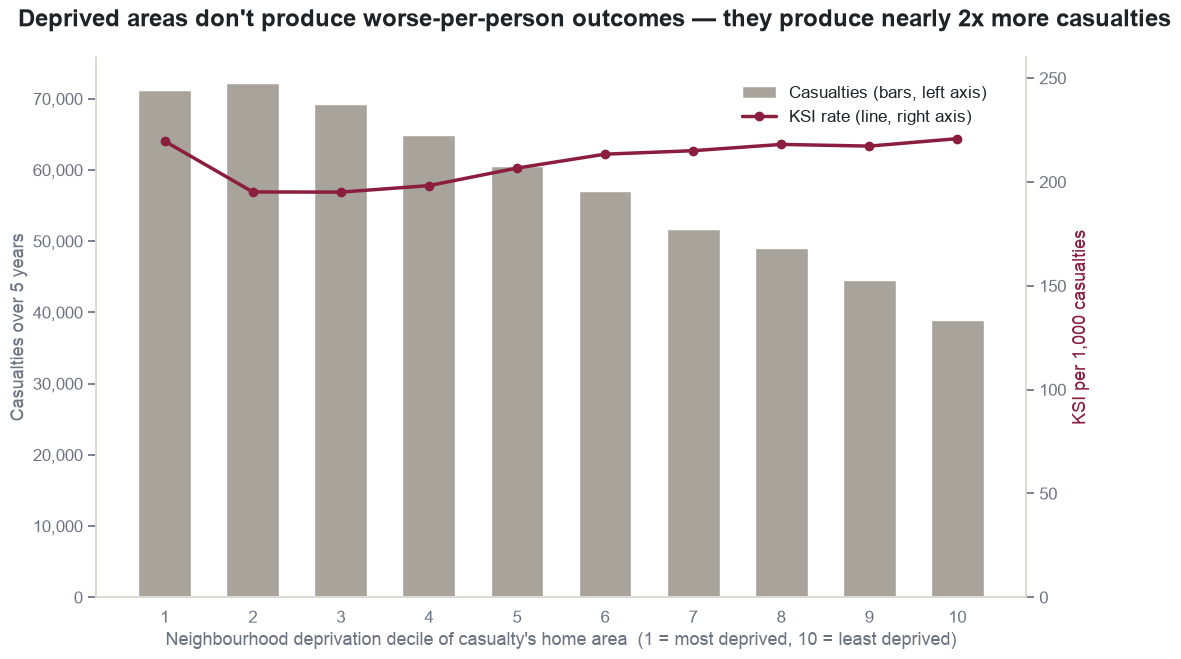


Most-deprived decile has 1.83x the casualties of the least-deprived decile.
KSI rate range across deciles: 195 - 221 per 1,000 (comparatively flat)


In [21]:
imd = (
    joined[joined["casualty_imd_decile"].between(1, 10)]
    .groupby("casualty_imd_decile")
    .agg(casualties=("ksi", "size"), ksi=("ksi", "sum"))
    .reset_index()
)
imd["ksi_per_1000"] = 1000 * imd["ksi"] / imd["casualties"]
print(imd)

fig, ax1 = plt.subplots(figsize=VIDEO_FIG)
ax1.bar(imd["casualty_imd_decile"], imd["casualties"], color=PROTECTED_COLOUR, width=0.6, label="Casualties (bars, left axis)")
ax1.set_xlabel("Neighbourhood deprivation decile of casualty's home area  (1 = most deprived, 10 = least deprived)")
ax1.set_ylabel("Casualties over 5 years")
ax1.set_xticks(range(1, 11))
ax1.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}")

ax2 = ax1.twinx()
ax2.plot(imd["casualty_imd_decile"], imd["ksi_per_1000"], color=KSI_COLOUR, linewidth=2.5, marker="o", label="KSI rate (line, right axis)")
ax2.set_ylabel("KSI per 1,000 casualties", color=KSI_COLOUR)
ax2.set_ylim(0, 260)

headline(fig, "Deprived areas don't produce worse-per-person outcomes — they produce nearly 2x more casualties")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.89), fontsize=12, frameon=False)
sns.despine(right=False)
save(fig, "09_deprivation.png")
plt.show()

ratio = imd.loc[imd["casualty_imd_decile"] == 1, "casualties"].iloc[0] / imd.loc[imd["casualty_imd_decile"] == 10, "casualties"].iloc[0]
print(f"\nMost-deprived decile has {ratio:.2f}x the casualties of the least-deprived decile.")
print(f"KSI rate range across deciles: {imd['ksi_per_1000'].min():.0f} - {imd['ksi_per_1000'].max():.0f} per 1,000 (comparatively flat)")

**What this shows:** for each neighbourhood deprivation level (1 = most deprived area, 10 = least deprived), how many casualties come from there, and how severe their injuries were.

**What it means:** the severity line barely moves — it stays in a narrow 195–220 per 1,000 band everywhere. But the number of casualties isn't flat at all: the most deprived areas have **71,234 casualties over 5 years, versus 38,899 in the least deprived — 1.8× more.** So it's not that poorer areas get hurt worse — they just get hurt more often. A second, separate inequality that chart 1's single average completely missed.

**The same two facts, on one axis.** The chart above needs two different axes to show two measures. Here each bar is simply everyone hurt, with the KSI casualties in red at the bottom, so both facts can be read from the same bars.

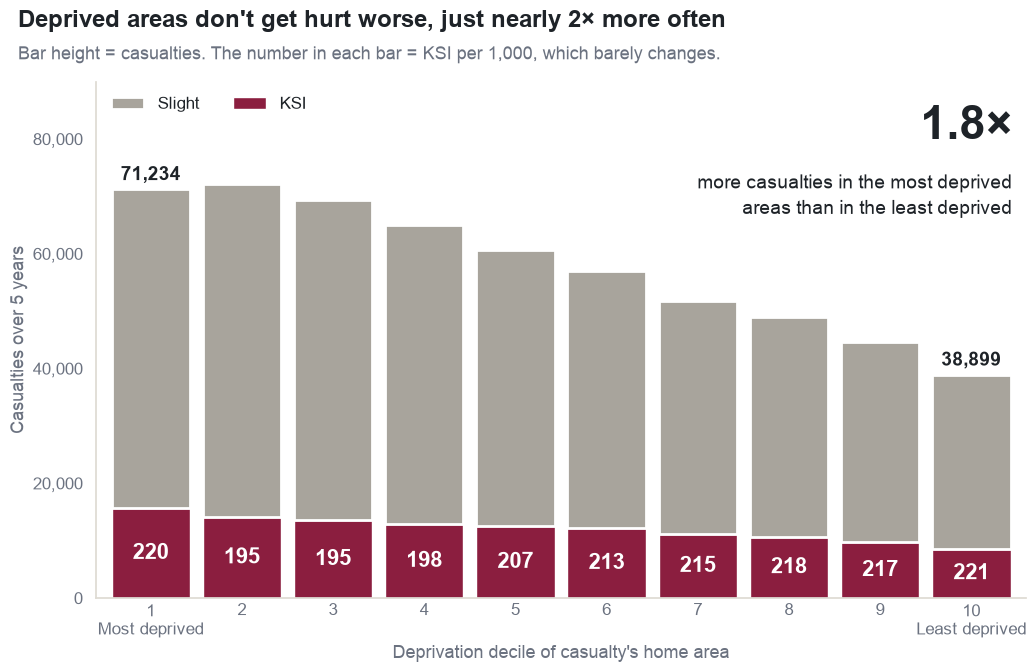

In [22]:
fig, ax = plt.subplots(figsize=VIDEO_FIG)
deciles = imd["casualty_imd_decile"]
ax.bar(deciles, imd["ksi"], width=0.86, color=KSI_COLOUR, label="KSI", zorder=2)
ax.bar(deciles, imd["casualties"] - imd["ksi"], bottom=imd["ksi"], width=0.86, color=SEVERITY_COLOURS["Slight"],
       edgecolor="white", linewidth=2, label="Slight", zorder=2)

# the rate sits inside the KSI part, so "same severity" reads off every bar
for row in imd.itertuples():
    ax.text(row.casualty_imd_decile, row.ksi / 2, f"{row.ksi_per_1000:.0f}", ha="center", va="center",
            fontsize=16, fontweight="bold", color="white", zorder=3)

for decile in [1, 10]:
    total = imd.loc[imd["casualty_imd_decile"] == decile, "casualties"].iloc[0]
    ax.text(decile, total + 900, f"{total:,}", ha="center", va="bottom", fontsize=14, fontweight="bold")

ax.text(10.45, 86000, f"{ratio:.1f}×", ha="right", va="top", fontsize=34, fontweight="bold")
ax.text(10.45, 74500, "more casualties in the most deprived\nareas than in the least deprived", ha="right", va="top",
        fontsize=14, linespacing=1.4)

ax.set_xticks(range(1, 11), ["1\nMost deprived", *map(str, range(2, 10)), "10\nLeast deprived"])
ax.set_xlim(0.4, 10.6)
ax.set_ylim(0, 90000)
ax.set_yticks(range(0, 90000, 20000))
ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}")
ax.set_xlabel("Deprivation decile of casualty's home area")
ax.set_ylabel("Casualties over 5 years")
ax.tick_params(axis="x", length=0)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left", frameon=False, ncol=2)
sns.despine()
headline(fig, "Deprived areas don't get hurt worse, just nearly 2× more often",
         "Bar height = casualties. The number in each bar = KSI per 1,000, which barely changes.")
save(fig, "09_deprivation_stacked.png")
plt.show()


**What this shows:** one bar for each tenth of areas, from most to least deprived. The height of the bar is how many casualties came from there, and the number in the red part is their KSI rate per 1,000.

**What it means:** the bars shrink from left to right, but the number inside them stays in the same narrow 195–221 band. So people from deprived areas aren't hurt worse once they're in a crash. There are simply more of them: 71,234 against 38,899, or 1.8× more.

**What we're checking:** so far "motorcyclist" has been treated as one group. But a small moped and a big superbike are very different. Does engine size change the risk? And what about e-scooters, a newer mode this data barely used to capture?

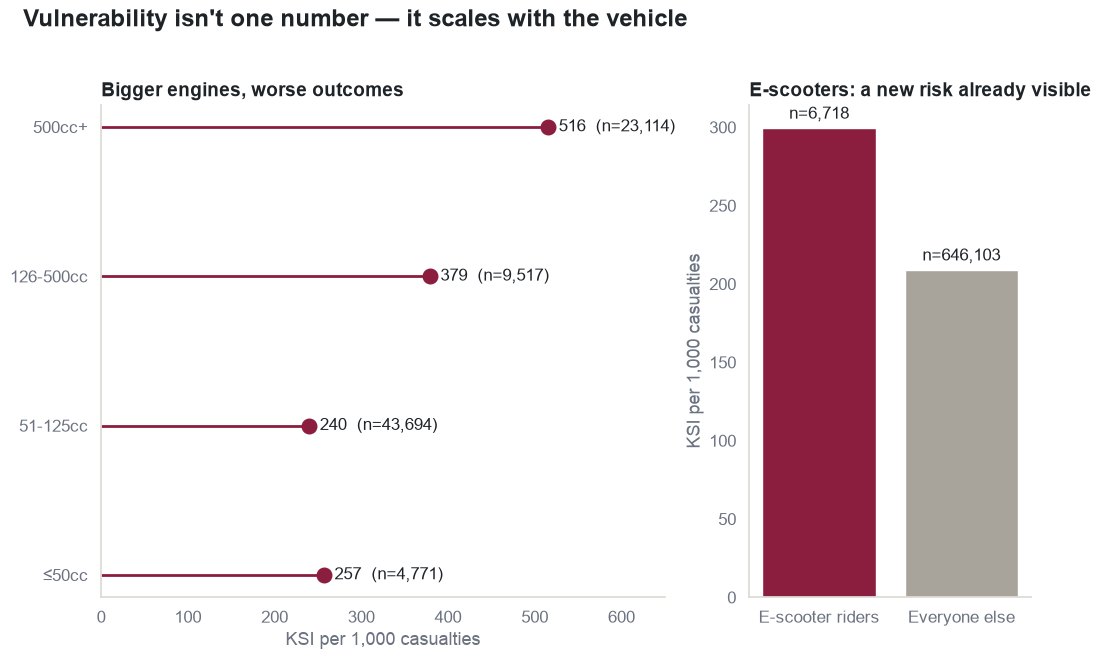

In [23]:
MOTORCYCLE_ENGINE_LABELS = {2: "≤50cc", 3: "51-125cc", 4: "126-500cc", 5: "500cc+"}

mc = joined[joined["vehicle_type"].isin(MOTORCYCLE_ENGINE_LABELS)].copy()
mc["engine_band"] = mc["vehicle_type"].map(MOTORCYCLE_ENGINE_LABELS)
mc_rates = (
    mc.groupby("engine_band")
    .agg(casualties=("ksi", "size"), ksi=("ksi", "sum"))
    .reindex(["≤50cc", "51-125cc", "126-500cc", "500cc+"])
    .reset_index()
)
mc_rates["ksi_per_1000"] = 1000 * mc_rates["ksi"] / mc_rates["casualties"]

esc = joined.groupby(joined["escooter_flag"].map({0: "Everyone else", 1: "E-scooter riders"})).agg(
    casualties=("ksi", "size"), ksi=("ksi", "sum")
).reset_index().rename(columns={"escooter_flag": "group"})
esc["ksi_per_1000"] = 1000 * esc["ksi"] / esc["casualties"]

fig, axes = plt.subplots(1, 2, figsize=VIDEO_FIG, gridspec_kw={"width_ratios": [2, 1]})

ax = axes[0]
ax.hlines(mc_rates["engine_band"], 0, mc_rates["ksi_per_1000"], color=EXPOSED_COLOUR, linewidth=2)
ax.scatter(mc_rates["ksi_per_1000"], mc_rates["engine_band"], color=EXPOSED_COLOUR, s=110, zorder=3)
for _, row in mc_rates.iterrows():
    ax.text(row["ksi_per_1000"] + 12, row["engine_band"], f"{row['ksi_per_1000']:.0f}  (n={row['casualties']:,})", va="center", fontsize=12)
ax.set_xlim(0, 650)
ax.set_title("Bigger engines, worse outcomes")
ax.set_xlabel("KSI per 1,000 casualties")
ax.set_ylabel(None)

ax2 = axes[1]
bars = ax2.bar(esc["group"], esc["ksi_per_1000"], color=[KSI_COLOUR, PROTECTED_COLOUR])
for b, row in zip(bars, esc.itertuples()):
    ax2.text(b.get_x() + b.get_width() / 2, b.get_height() + 6, f"n={row.casualties:,}", ha="center", fontsize=12)
ax2.set_title("E-scooters: a new risk already visible")
ax2.set_ylabel("KSI per 1,000 casualties")

sns.despine()
headline(fig, "Vulnerability isn't one number — it scales with the vehicle")
fig.subplots_adjust(top=0.84)
save(fig, "10_vehicle_power.png")
plt.show()

**What this shows:** KSI rate for motorcyclists, split by engine size, plus e-scooter riders vs. everyone else.

**What it means:** bigger, faster motorcycles are considerably more dangerous — 500cc+ bikes have a KSI rate of **515 per 1,000** (more than half end up KSI), exactly **2×** the rate for sub-50cc machines (257 per 1,000). "Exposed" isn't one risk level — it has its own gradient. E-scooter riders also show a **43% higher** KSI rate than everyone else (299 vs 209 per 1,000), though on a smaller sample (n=6,718) — worth watching, not yet a settled trend.

**What we're checking:** does *when* a crash happens change how severe it is? For every hour of every day of the week, what share of casualties are KSI? A heatmap fits all 168 time slots (24 hours × 7 days) in one picture, which a bar or line chart couldn't manage cleanly.

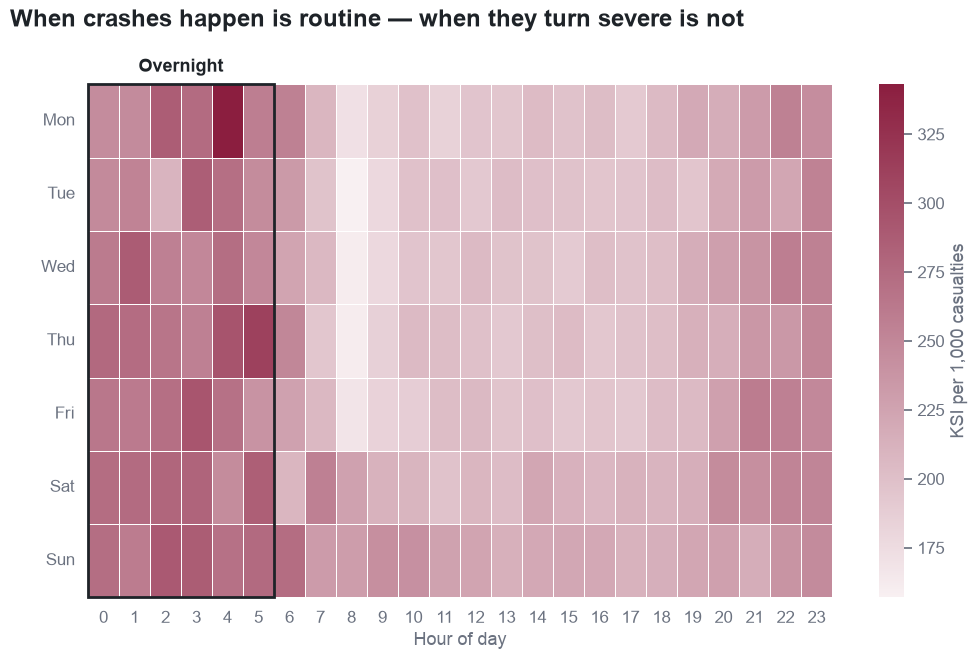

Worst cell: Mon 04:00 - 343 per 1,000 (n=446)


In [24]:
DAY_LABELS = {1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"}
DAY_ORDER = [2, 3, 4, 5, 6, 7, 1]

time_df = joined.dropna(subset=["time", "day_of_week"]).copy()
time_df["hour"] = time_df["time"].str.slice(0, 2).astype(int)
time_df["day_label"] = time_df["day_of_week"].map(DAY_LABELS)

heat = (
    time_df.groupby(["day_of_week", "hour"])
    .agg(casualties=("ksi", "size"), ksi=("ksi", "sum"))
    .reset_index()
)
heat = heat[heat["casualties"] >= 50]
heat["ksi_per_1000"] = 1000 * heat["ksi"] / heat["casualties"]
pivot = heat.pivot(index="day_of_week", columns="hour", values="ksi_per_1000").reindex(DAY_ORDER)
pivot.index = [DAY_LABELS[d] for d in DAY_ORDER]

fig, ax = plt.subplots(figsize=VIDEO_FIG)
sns.heatmap(pivot, cmap=HARM_RAMP, ax=ax, cbar_kws={"label": "KSI per 1,000 casualties"}, linewidths=0.4, linecolor="#FFFFFF")
headline(fig, "When crashes happen is routine — when they turn severe is not")
ax.add_patch(plt.Rectangle((0, 0), 6, 7, fill=False, edgecolor=INK, linewidth=2, clip_on=False, zorder=3))
ax.text(3, -0.12, "Overnight", ha="center", va="bottom", fontsize=13, fontweight="bold")
ax.tick_params(axis="y", labelrotation=0)
fig.subplots_adjust(top=0.87)
ax.set_xlabel("Hour of day")
ax.set_ylabel(None)
save(fig, "11_time_heatmap.png")
plt.show()

worst = heat.loc[heat["ksi_per_1000"].idxmax()]
print(f"Worst cell: {DAY_LABELS[int(worst['day_of_week'])]} {int(worst['hour']):02d}:00 - {worst['ksi_per_1000']:.0f} per 1,000 (n={int(worst['casualties'])})")

**What this shows:** KSI rate for every hour of every day, as a grid of colours — darker means more severe.

**What it means:** daytime hours (roughly 7am–9pm) stay in a narrow 180–220 per 1,000 band, any day of the week. But overnight — midnight to about 6am, **every single night**, not just weekends — KSI rates climb above 300, peaking past 340 on some nights. Fewer crashes happen overnight, but the ones that do are far more likely to be severe. Something the daytime-only speed-limit chart couldn't show.

---
# Back to where we started

A good story ends by returning to the first picture — and showing it can't be read the same innocent way anymore.

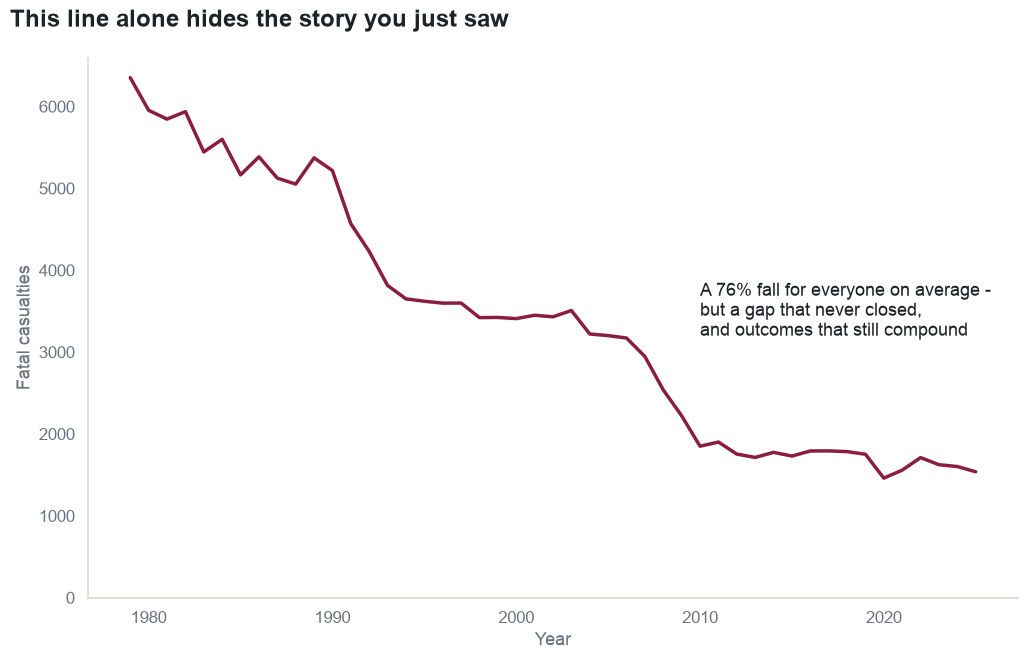

In [25]:
fig, ax = plt.subplots(figsize=VIDEO_FIG)
sns.lineplot(data=fatal_by_year, x="year", y="casualties", color=EXPOSED_COLOUR, ax=ax, linewidth=2.5)
headline(fig, "This line alone hides the story you just saw")
ax.set_xlabel("Year")
ax.set_ylabel("Fatal casualties")
ax.set_ylim(0, None)
ax.annotate(
    "A 76% fall for everyone on average -\nbut a gap that never closed,\nand outcomes that still compound",
    xy=(2010, 3200), fontsize=13, ha="left",
)
sns.despine()
save(fig, "07_bookend.png")
plt.show()

**What this shows:** the exact same chart as chart 1 — deaths by year — shown again.

**What it means:** it's the same line, but you can't read it the same way now. Everything in between showed the 76% improvement wasn't shared equally, and today's worst outcomes still come from risks stacking on the same person.

## The whole story, in plain English

One line (chart 1) says road deaths fell 76% since 1979 — 6,352 down to 1,538 a year. Looks like a finished success story, with one real, explainable blip in 2020 from COVID.

Split that line in two (chart 2) and the success story cracks: people with nothing protecting them (pedestrians, cyclists, motorcyclists) were about 1.5× more likely to die if hurt in the 1980s — and that gap actually *grew* to 2.3× through the 2000s–2010s, before settling at 1.7× today. Still worse than when records began. The single average line hid this completely.

Ask why (chart 3) and the obvious answer — "they must be out on worse roads" — turns out false. Matched on the exact same road, lighting, and area, unprotected people still come off 2–3× worse, every time (2.1×–3.3× across eight tested combinations). It isn't the road. It's the lack of a shell around them.

Stack risky conditions on top of that (chart 4) and the two things multiply rather than add: the worst real combination (no protection, fast dark rural road) is over 5× worse than the best (protected, slow daylight city road) — 105 per 1,000 up to 569. Losing protection multiplies risk by about 2–3×; bad conditions multiply it by about another 2.3×. Multiply those together and you land almost exactly on the 5.4× actually observed. If the two only added up, the worst case would be 390; if they multiplied, 582. The real figure is 569.

Three more checks fill in the picture: overall, **1 in 5** casualties (21.0%) is KSI (chart 5); speed limit raises severity up to 60mph, and the drop on 70mph motorways only exists for protected road users, while exposed ones keep climbing (chart 6); and a pictogram (chart 7) shows the same protection gap as a visible shift — car occupants shrink from 53% to 38% of the worst-hurt group, while pedestrians (14%→21%) and motorcyclists (12%→20%) grow.

Then the same question — do risks stack and multiply? — gets asked on four more things, to check it wasn't a fluke: **age** (chart 8) is its own risk factor, safest at 26–45, worst at the very young and very old (up to 336 per 1,000); **neighbourhood wealth** (chart 9) is a *different* kind of inequality — not worse injuries, just 1.8× more of them in the most deprived areas; **engine size** (chart 10) shows risk keeps climbing even inside the "exposed" group, from 257 to 515 per 1,000 for bigger motorcycles, with e-scooters already running 43% hotter than everyone else; and **time of day** (chart 11) shows the same severity spike every single night, hidden inside daily averages the same way the protection gap was hidden inside the yearly average.

Finally, the last chart (12) returns to the exact line we opened with. It hasn't changed — but it can't be read the same innocent way anymore.

## The facts, for reference

- Deaths fell 76% from 1979 to 2025 (6,352 → 1,538), with a genuine, explainable COVID dip in 2020 (−17%, to 1,460).
- Exposed-vs-protected death gap: 1.5× (1980s) → 2.3× peak (2000s–2010s) → 1.7× (now).
- In matched conditions, exposed road users have a 2.1×–3.3× higher KSI rate than protected ones.
- Stacking "no protection" + "bad conditions": 105 → 569 KSI per 1,000 (5.4× total = ~2.4× vulnerability × ~2.3× conditions). Additive prediction 390, multiplicative prediction 582.
- Overall, 21.0% of casualties are KSI (79.0% slight, 19.8% serious, 1.2% fatal).
- KSI rate by speed limit: 182 (20mph) → 282 (60mph) → 190 (70mph motorways). At 60 → 70mph: protected 227 → 162, exposed 541 → 551.
- Pictogram shift (casualty share → KSI share): car occupants 53%→38% (−15.5pp); pedestrians 14%→21% (+6.8pp); motorcyclists 12%→20% (+7.8pp); cyclists 12%→14% (+2.3pp).
- KSI rate by age: lowest 181–182 (26–45), highest 336 (75+); teenagers elevated at 218–231.
- Most vs. least deprived area: 1.8× more casualties (71,234 vs 38,899), but KSI rate barely moves (195–220 throughout).
- Motorcycle KSI rate by engine size: 257 (≤50cc) → 515 (500cc+); e-scooters 299 vs 209 for everyone else (43% higher, n=6,718).
- Overnight (midnight–6am) KSI rate stays above 300, every night, vs. 180–220 in the daytime.

**One sentence to remember:** nearly 50 years of real progress on Britain's roads didn't reach everyone equally — not because some people are unlucky enough to face worse conditions, but because they are two to three times more vulnerable in identical conditions, and today's worst outcomes come from that vulnerability stacking with bad conditions on the same person at once — a pattern that shows up again and again, on every variable this notebook checked.